# Patient Health Time-Series Forecasting Using LSTM
Predict a patient's **next-hour heart rate** from the previous 24 hours of vital signs.

**Steps:** load data → explore → preprocess → build sequences → LSTM model → train → evaluate

## 0. Install Required Packages
Run this cell once, then **restart the kernel** (Kernel → Restart) and run the notebook from the top.

In [1]:
%pip install tensorflow scikit-learn pandas matplotlib

   ---------------------------------------- 0.0/382.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/382.7 MB 6.2 MB/s eta 0:01:02
   ---------------------------------------- 2.1/382.7 MB 6.0 MB/s eta 0:01:04
   ---------------------------------------- 3.4/382.7 MB 6.2 MB/s eta 0:01:02
   ---------------------------------------- 4.7/382.7 MB 6.0 MB/s eta 0:01:03
    --------------------------------------- 6.0/382.7 MB 6.0 MB/s eta 0:01:03
    --------------------------------------- 7.1/382.7 MB 6.1 MB/s eta 0:01:02
    --------------------------------------- 8.7/382.7 MB 6.1 MB/s eta 0:01:01
   - -------------------------------------- 10.0/382.7 MB 6.2 MB/s eta 0:01:00
   - -------------------------------------- 11.5/382.7 MB 6.3 MB/s eta 0:00:59
   - -------------------------------------- 12.6/382.7 MB 6.2 MB/s eta 0:01:00
   - -------------------------------------- 13.9/382.7 MB 6.2 MB/s eta 0:01:00
   - -------------------------------------- 15.2/382.7 MB 6.2 MB/s 

## 1. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

Matplotlib is building the font cache; this may take a moment.


## 2. Load Dataset

In [5]:
df = pd.read_csv('patient_health_timeseries_lstm.csv', parse_dates=['timestamp'])
df.head()

,patient_id,timestamp,age,gender,heart_rate_bpm,systolic_bp_mmhg,diastolic_bp_mmhg,body_temperature_c,spo2_percent,respiratory_rate_bpm,blood_glucose_mg_dl,target_next_hour_heart_rate_bpm
0,P001,2025-01-01 00:00:00,24,Female,67.24,124.28,82.03,36.36,96.24,16.35,98.15,64.05
1,P001,2025-01-01 01:00:00,24,Female,64.05,124.80,82.73,36.33,96.52,16.02,95.71,68.60
2,P001,2025-01-01 02:00:00,24,Female,68.60,125.45,82.75,36.32,96.24,16.62,96.33,70.52
3,P001,2025-01-01 03:00:00,24,Female,70.52,130.70,85.86,36.33,95.89,16.24,98.31,68.20
4,P001,2025-01-01 04:00:00,24,Female,68.20,128.22,84.74,36.33,96.33,16.29,100.19,69.84


## 3. Explore the Data

In [6]:
print(df.shape)
print('Patients:', df['patient_id'].nunique())
print('Rows per patient:', df.groupby('patient_id').size().unique())
print('Missing values:', df.isna().sum().sum())

(9980, 12)
Patients: 20
Rows per patient: [499]
Missing values: 0


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,9980,2025-01-11 09:00:00,2025-01-01 00:00:00,2025-01-06 04:00:00,2025-01-11 09:00:00,2025-01-16 14:00:00,2025-01-21 18:00:00,NaN
age,9980.0,46.75,19.0,29.5,50.0,58.0,81.0,18.407103
heart_rate_bpm,9980.0,75.509399,52.0,70.555,75.51,80.62,102.42,7.634857
systolic_bp_mmhg,9980.0,122.371776,96.54,116.5775,122.81,128.1,152.0,8.377884
diastolic_bp_mmhg,9980.0,77.822632,59.68,73.49,78.55,82.19,94.33,5.794388
body_temperature_c,9980.0,36.792216,36.07,36.6,36.78,36.96,37.61,0.261618
spo2_percent,9980.0,97.063513,94.37,96.39,97.08,97.69,100.0,0.952308
respiratory_rate_bpm,9980.0,16.765425,10.41,15.62,16.71,17.85,22.84,1.750752
blood_glucose_mg_dl,9980.0,102.175625,65.0,92.41,101.52,111.9375,151.29,15.57463
target_next_hour_heart_rate_bpm,9980.0,75.514001,52.0,70.5675,75.52,80.62,102.42,7.634093


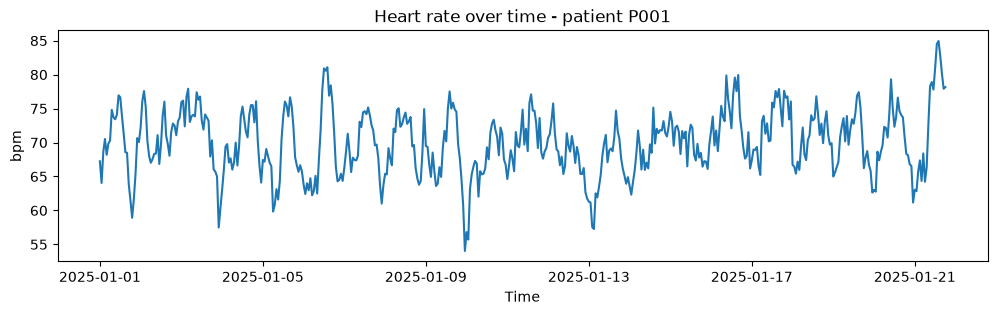

In [8]:
p = df[df['patient_id'] == 'P001']
plt.figure(figsize=(12, 3))
plt.plot(p['timestamp'], p['heart_rate_bpm'])
plt.title('Heart rate over time - patient P001')
plt.xlabel('Time'); plt.ylabel('bpm')
plt.show()

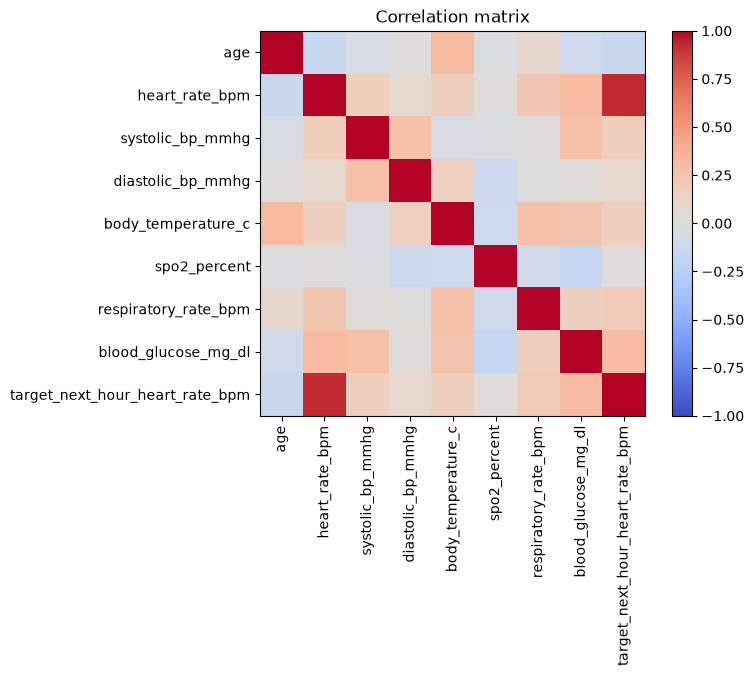

In [9]:
plt.figure(figsize=(7, 5))
corr = df.drop(columns=['patient_id', 'timestamp', 'gender']).corr()
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar(); plt.title('Correlation matrix')
plt.show()

## 4. Preprocessing
Sort by patient and time, then encode gender as a number.

In [11]:
df = df.sort_values(['patient_id', 'timestamp']).reset_index(drop=True)
df['gender_enc'] = (df['gender'] == 'Male').astype(int)

features = ['heart_rate_bpm', 'systolic_bp_mmhg', 'diastolic_bp_mmhg',
            'body_temperature_c', 'spo2_percent', 'respiratory_rate_bpm',
            'blood_glucose_mg_dl', 'age', 'gender_enc']
target = 'target_next_hour_heart_rate_bpm'
WINDOW = 24   # hours of history used for each prediction

### Chronological split per patient (70% train / 15% validation / 15% test)
Splitting by time avoids leaking future data into training.

In [12]:
train_parts, val_parts, test_parts = [], [], []
for pid, g in df.groupby('patient_id'):
    n = len(g)
    i1, i2 = int(n * 0.70), int(n * 0.85)
    train_parts.append(g.iloc[:i1])
    val_parts.append(g.iloc[i1:i2])
    test_parts.append(g.iloc[i2:])

train_df = pd.concat(train_parts)
val_df = pd.concat(val_parts)
test_df = pd.concat(test_parts)
print(len(train_df), len(val_df), len(test_df))

6980 1500 1500


### Scale features and target (fit on training data only)

In [13]:
x_scaler = StandardScaler().fit(train_df[features])
y_scaler = StandardScaler().fit(train_df[[target]])

def scale(part):
    part = part.copy()
    part[features] = x_scaler.transform(part[features])
    part[target] = y_scaler.transform(part[[target]])
    return part

train_s, val_s, test_s = scale(train_df), scale(val_df), scale(test_df)

## 5. Create Sequences
Each sample = last 24 hours of features for one patient; label = next-hour heart rate.

In [14]:
def make_sequences(part, window=WINDOW):
    X, y = [], []
    for pid, g in part.groupby('patient_id'):
        f = g[features].values
        t = g[target].values
        for i in range(window, len(g) + 1):
            X.append(f[i - window:i])
            y.append(t[i - 1])
    return np.array(X, dtype='float32'), np.array(y, dtype='float32')

In [15]:
X_train, y_train = make_sequences(train_s)
X_val, y_val = make_sequences(val_s)
X_test, y_test = make_sequences(test_s)
print('Train:', X_train.shape, y_train.shape)
print('Val:  ', X_val.shape, y_val.shape)
print('Test: ', X_test.shape, y_test.shape)

Train: (6520, 24, 9) (6520,)
Val:   (1040, 24, 9) (1040,)
Test:  (1040, 24, 9) (1040,)


## 6. Build the LSTM Model

In [16]:
model = Sequential([
    Input(shape=(WINDOW, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 24, 64)              │          18,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31,905 (124.63 KB)

 Trainable params: 31,905 (124.63 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the Model

In [17]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - loss: 0.4743 - mae: 0.5431 - val_loss: 0.3299 - val_mae: 0.4588
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - loss: 0.2696 - mae: 0.4141 - val_loss: 0.2370 - val_mae: 0.3910
Epoch 3/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - loss: 0.2080 - mae: 0.3649 - val_loss: 0.1988 - val_mae: 0.3586
Epoch 4/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.1898 - mae: 0.3482 - val_loss: 0.1814 - val_mae: 0.3434
Epoch 5/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.1710 - mae: 0.3307 - val_loss: 0.1694 - val_mae: 0.3329
Epoch 6/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.1612 - mae: 0.3219 - val_loss: 0.1589 - val_mae: 0.3221
Epoch 7/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.1524 - mae: 0.3116 - val_loss: 0.1517 - val_mae: 0.3155
Epoch 8/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.1492 - mae: 0.3091 - val_loss: 0.1478 - val_mae: 0.3107
Epoch 9/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 6s 34m

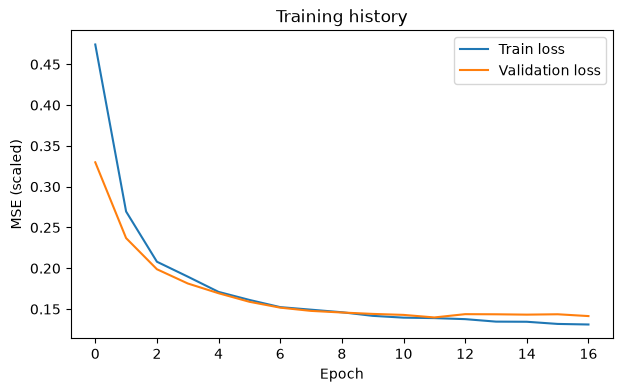

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE (scaled)')
plt.title('Training history'); plt.legend()
plt.show()

## 8. Evaluate on the Test Set
Predictions are converted back to bpm.

In [19]:
pred_s = model.predict(X_test, verbose=0)
y_pred = y_scaler.inverse_transform(pred_s).ravel()
y_true = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)
print(f'LSTM  -> MAE: {mae:.2f} bpm | RMSE: {rmse:.2f} bpm | R2: {r2:.3f}')

LSTM  -> MAE: 2.22 bpm | RMSE: 2.82 bpm | R2: 0.865


### Baseline comparison
Simple baseline: predict that next hour's heart rate equals the current heart rate.

In [20]:
hr_idx = features.index('heart_rate_bpm')
cur_hr_s = X_test[:, -1, hr_idx]
cur_hr = x_scaler.mean_[hr_idx] + cur_hr_s * x_scaler.scale_[hr_idx]

b_mae = mean_absolute_error(y_true, cur_hr)
b_rmse = np.sqrt(mean_squared_error(y_true, cur_hr))
b_r2 = r2_score(y_true, cur_hr)
print(f'Baseline -> MAE: {b_mae:.2f} bpm | RMSE: {b_rmse:.2f} bpm | R2: {b_r2:.3f}')

Baseline -> MAE: 2.41 bpm | RMSE: 3.03 bpm | R2: 0.844


## 9. Visualize Predictions

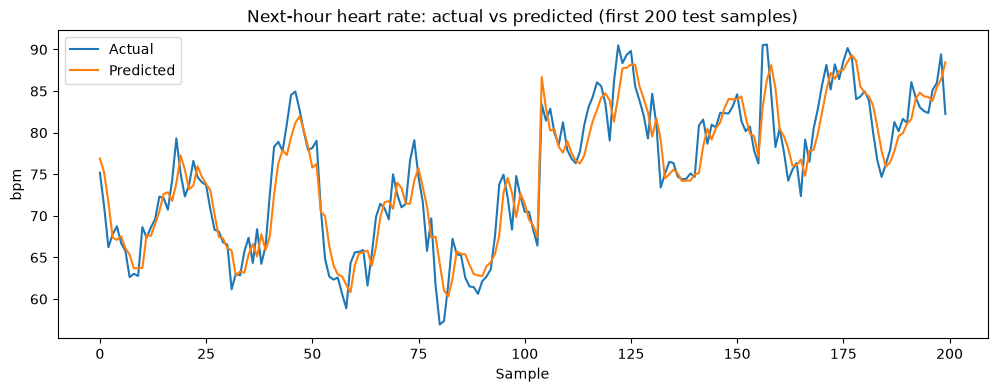

In [21]:
plt.figure(figsize=(12, 4))
plt.plot(y_true[:200], label='Actual')
plt.plot(y_pred[:200], label='Predicted')
plt.title('Next-hour heart rate: actual vs predicted (first 200 test samples)')
plt.xlabel('Sample'); plt.ylabel('bpm'); plt.legend()
plt.show()

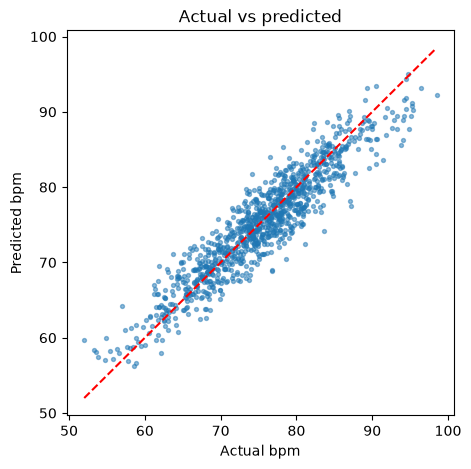

In [22]:
plt.figure(figsize=(5, 5))
plt.scatter(y_true, y_pred, s=8, alpha=0.5)
lims = [y_true.min(), y_true.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual bpm'); plt.ylabel('Predicted bpm')
plt.title('Actual vs predicted')
plt.show()

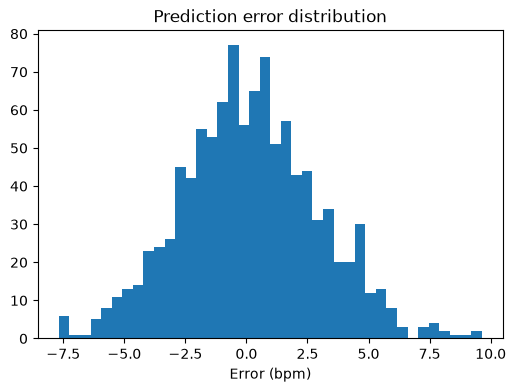

In [23]:
errors = y_true - y_pred
plt.figure(figsize=(6, 4))
plt.hist(errors, bins=40)
plt.title('Prediction error distribution'); plt.xlabel('Error (bpm)')
plt.show()

## 10. Save the Model

In [24]:
model.save('patient_hr_lstm.keras')

## 11. Conclusion
- An LSTM trained on 24-hour windows of vital signs forecasts next-hour heart rate.
- Compare the LSTM's MAE/RMSE/R² with the persistence baseline above to judge the benefit of the model.
- Possible improvements: longer window, a GRU or bidirectional LSTM, hyperparameter tuning, or per-patient models.